In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

data = {
    "Student" : ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O"],
    "Study_Hours" : [2,3,4,5,4,6,5,3,4,5,6,4,5,30,3]
}
df = pd.DataFrame(data)
print("Original dataset")
display(df)

Original dataset


,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [4]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,5.933333
std,6.755597
min,2.000000
25%,3.500000
50%,4.000000
75%,5.000000
max,30.000000


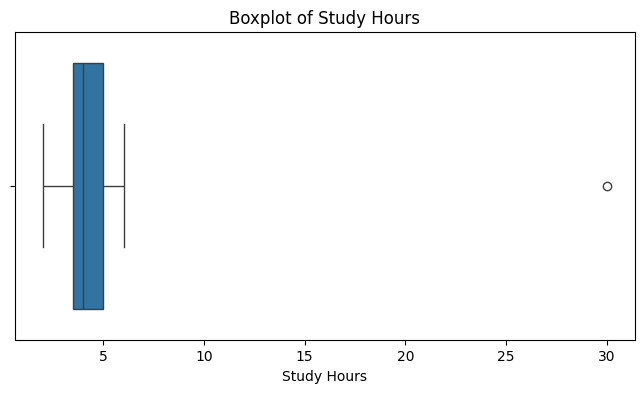

In [5]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["Study_Hours"])
plt.title("Boxplot of Study Hours")
plt.xlabel("Study Hours")
plt.show()

In [6]:
Q1 = df["Study_Hours"].quantile(0.25)
Q3 = df["Study_Hours"].quantile(0.75)
print("Q1: ",Q1)
print("Q3: ",Q3)

Q1:  3.5
Q3:  5.0


In [7]:
IQR = Q3 - Q1
print("IQR: ",IQR)

IQR:  1.5


In [8]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Lower Bound: ",lower_bound)
print("Upper Bound: ",upper_bound)

Lower Bound:  1.25
Upper Bound:  7.25


In [9]:
outliers_iqr = df[(df["Study_Hours"] < lower_bound) | (df["Study_Hours"] > upper_bound)]
print("Outliers using IQR:")
display(outliers_iqr)

Outliers using IQR:


,Student,Study_Hours
13,N,30


In [10]:
normal_data_iqr = df[(df["Study_Hours"] >= lower_bound) & (df["Study_Hours"] <= upper_bound)]
print("Normal Data using IQR:")
display(normal_data_iqr)

Normal Data using IQR:


,Student,Study_Hours
0,A,2
1,B,3
2,C,4
3,D,5
4,E,4
5,F,6
6,G,5
7,H,3
8,I,4
9,J,5


In [11]:
df["Z_Score"] = zscore(df["Study_Hours"])
print("Dataset with Z-Score:")
display(df)

Dataset with Z-Score:


,Student,Study_Hours,Z_Score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [12]:
z_outliers = (df["Z_Score"] > 3) | (df["Z_Score"] < -3)
print("Outliers using Z-Score:")
display(z_outliers)

Outliers using Z-Score:


,Z_Score
0,False
1,False
2,False
3,False
4,False
5,False
6,False
7,False
8,False
9,False


In [13]:
df_without_outliers = df[(df["Study_Hours"] >= lower_bound) & (df["Study_Hours"] <= upper_bound)]
display(df_without_outliers)

,Student,Study_Hours,Z_Score
0,A,2,-0.602669
1,B,3,-0.449448
2,C,4,-0.296227
3,D,5,-0.143006
4,E,4,-0.296227
5,F,6,0.010215
6,G,5,-0.143006
7,H,3,-0.449448
8,I,4,-0.296227
9,J,5,-0.143006


In [14]:
df_capped = df.copy()
df_capped["Study_Hours"] = df_capped["Study_Hours"].clip(
    lower = lower_bound,
    upper = upper_bound
    )
display(df_capped)

,Student,Study_Hours,Z_Score
0,A,2.00,-0.602669
1,B,3.00,-0.449448
2,C,4.00,-0.296227
3,D,5.00,-0.143006
4,E,4.00,-0.296227
5,F,6.00,0.010215
6,G,5.00,-0.143006
7,H,3.00,-0.449448
8,I,4.00,-0.296227
9,J,5.00,-0.143006


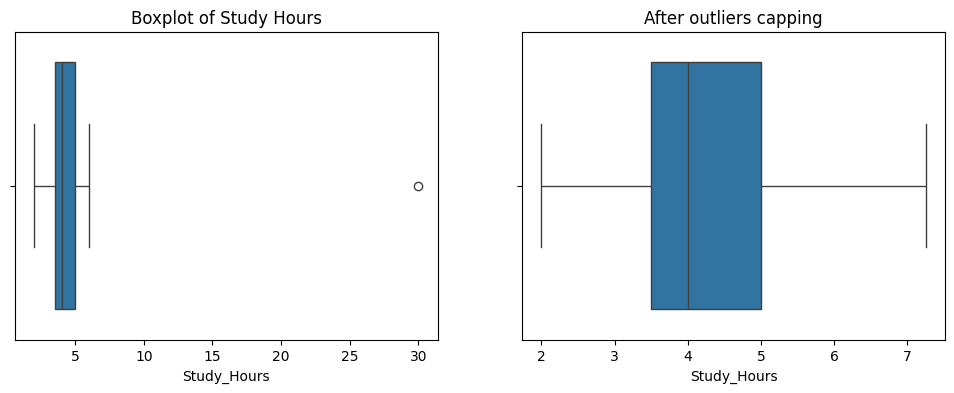

In [16]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.boxplot(x=df["Study_Hours"])
plt.title("Boxplot of Study Hours")

plt.subplot(1,2,2)
sns.boxplot(x=df_capped["Study_Hours"])
plt.title("After outliers capping")

plt.show()